# FMNs Analysis

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import json
import glob
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm

# Add project root for src/ imports
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from src.models_and_vars import load_env_vars, ensure_nltk_path, init_spacy_and_emo
from src.io import import_fmnt_from_txt, export_df
from src.valence import fmn_valence_stats
from src.fmtools import verify_and_report_nodes
from src.analysis import (
    compare_fmns_patterns,
    compute_auras_for_words,
    keyword_compound_index,
    keyword_correlometer_bulk,
    slope_compare_groups,
)

In [2]:
# you do not need to run these download commands every time. nltk.download()
# saves these data packages to your local file system in the nltk_data directory.
# Once they are downloaded, they are available for NLTK to use in any session.

'''nltk.download('wordnet')
nltk.download('omw-1.4') # for italian and multilingual support, if needed
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng') # for word tokenization
nltk.download('averaged_perceptron_tagger') # for POS tagging
'''


"nltk.download('wordnet')\nnltk.download('omw-1.4') # for italian and multilingual support, if needed\nnltk.download('punkt')\nnltk.download('punkt_tab')\nnltk.download('averaged_perceptron_tagger_eng') # for word tokenization\nnltk.download('averaged_perceptron_tagger') # for POS tagging\n"

# Environment and models settings

In [3]:
# Set language once; everything else adapts
language = "italian"  # or "english"
env_file_path = "../env"

# Execute setup
load_env_vars(env_file_path, language=language)
ensure_nltk_path()

nlp, emo = init_spacy_and_emo(language)

# Also preload both models for explicit use
nlp_en, _ = init_spacy_and_emo("english")
nlp_it, _ = init_spacy_and_emo("italian")

Loaded SPACY_MODEL_PATH_EN: /home/franaz/coding/spacy-models/en_core_web_lg/en_core_web_lg-3.8.0
Loaded SPACY_MODEL_PATH_IT: /home/franaz/coding/spacy-models/it_core_news_lg/it_core_news_lg-3.7.0
Loaded NLTK_DATA: /home/franaz/nltk_data



/home/franaz/coding/python/projects/data_science/networks/rassereno/.rassereno-py310/lib/python3.10/site-packages/spacy/util.py:922: UserWarning: [W095] Model 'it_core_news_lg' (3.7.0) was trained with spaCy v3.7.0 and may not be 100% compatible with the current version (3.8.7). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


# fmn settings

In [4]:
# Dynamic output paths system for pipelines
base_output_path = '../out'
exported_location = f"{base_output_path}/definitivo"
formatted_data_dir = 'formatting'
# Set the type of fmn to use: 'bfmns' or 'tfmns'
# (this is used for the folder name, not for the file names)
fmn_type = 'fmn'
# Keywords that we want to check for in the textual data. If not empty,
# semantic frame plots will be created for these keywords. Otherwise,
# the full FMNs will be visualized.
keywords = []
keywords = ['matematica','ansia','stress','depressione','statistica','informatica','fisica','scienza','prestazione','esame','voto','valutazione','scuola','competizione','università','calcolo','disciplina','materia']
# Dynamically extract project name from exported location and build name based on keywords
project_name = "concreteness_table"

# Lemmatization setting
lemmatize = False

# Types of output: aggregated and individual (entire dataset vs per participant FMNs)
# Choose any subset: {'aggregated'}, {'individual'}, or both
# How to use:
# Only aggregated: methods = {'aggregated'}
# Only individual: methods = {'individual'}
# Both: methods = {'aggregated', 'individual'}
ALLOWED_METHODS = {'aggregated', 'individual'}
methods = {'aggregated'}
methods = {m.strip().lower() for m in (methods if isinstance(methods, (list, set, tuple)) else [methods])}
methods = methods & ALLOWED_METHODS
if not methods:
    raise ValueError("No valid methods selected. Use 'aggregated' and/or 'individual'.")

# Groups to subset the data (if needed). Use labels and .startswith() condition
# from the 'participant_id' column to create groups.
group_name = 'all_fmns'  # fmn name when using groups
if group_name:
    fmn_type = f'{group_name}_{fmn_type}'


files_output_dir = f'{base_output_path}/{project_name}/analysis'
figures_output_dir = f'{base_output_path}/{project_name}/figures'

# Ensure the files and figures output directories exist
os.makedirs(files_output_dir, exist_ok=True)
os.makedirs(figures_output_dir, exist_ok=True)

# Print output folders
print(f"Output files will be in folder '{files_output_dir}'")
print(f"Output figures will be in folder '{figures_output_dir}'")

Output files will be in folder '../out/concreteness_table/analysis'
Output figures will be in folder '../out/concreteness_table/figures'


In [5]:
def create_concretess_table(significance_threshold: float = 0.1,
                            output_filename: str = "significant_concreteness_table_p_lt_0.1.csv"):
    """
    Build a table (DataFrame) of all (group, keyword) pairs whose concreteness
    analysis p-value is below significance_threshold, using every
    *concreteness_analysis.json found recursively under the `exported_location`
    (../out/definitivo).

    Parsing logic:
      - Group name is taken from the directory name before /analysis/, with any trailing
        '_bfmns' removed.
      - Keyword is the remainder of the file name after removing
        '<group>_' and the suffix '_concreteness_analysis.json'.

    Exports a UTF-8 CSV to files_output_dir.
    Returns the DataFrame (possibly empty if no significant results).
    """
    root = Path(exported_location)  # defined earlier in notebook
    pattern = "**/*concreteness_analysis.json"
    json_paths = list(root.glob(pattern))

    records = []
    for jp in json_paths:
        try:
            with jp.open("r", encoding="utf-8") as f:
                data = json.load(f)
        except Exception:
            continue  # skip unreadable

        p_val = data.get("p_value")
        u_stat = data.get("u_statistic")
        med_emp = data.get("median_empirical")
        med_rand = data.get("median_random")
        if p_val is None:
            continue

        # Derive group from directory name (parent of 'analysis')
        parts = jp.parts
        try:
            analysis_index = parts.index("analysis")
        except ValueError:
            group_dir_name = jp.parent.name
        else:
            group_dir_name = parts[analysis_index - 1] if analysis_index > 0 else jp.parent.name

        group = group_dir_name[:-6] if group_dir_name.endswith("_bfmns") else group_dir_name

        # Base filename without suffix
        base = jp.stem  # remove .json
        suffix = "_concreteness_analysis"
        if base.endswith(suffix):
            base = base[: -len(suffix)]

        # Keyword: remove leading '<group>_' if present
        if base.startswith(group + "_"):
            keyword = base[len(group) + 1 :]
        else:
            keyword = base.split("_")[-1]

        # Compute single n from empirical_scores length
        n_empirical = len(data.get("empirical_scores", []))

        records.append({
            "group": group,
            "keyword": keyword,
            "p_value": p_val,
            "u_statistic": u_stat,
            "median_empirical": med_emp,
            "median_random": med_rand,
            "median_diff": (med_emp - med_rand) if (med_emp is not None and med_rand is not None) else None,
            "n": n_empirical,
            "json_path": str(jp)
        })

    df = pd.DataFrame(records)
    if df.empty:
        print("No concreteness analysis files found.")
        return df

    # Filter by significance threshold
    sig_df = df[df["p_value"] < significance_threshold].copy()
    sig_df.sort_values(["p_value", "group", "keyword"], inplace=True)

    # Export
    out_path = Path(files_output_dir) / output_filename
    try:
        sig_df.to_csv(out_path, index=False, encoding="utf-8")
    except Exception as e:
        print(f"Failed to write CSV via pandas: {e}")

    print(f"Significant rows (p < {significance_threshold}): {len(sig_df)}")
    print(f"Exported to: {out_path}")

    try:
        display(sig_df)
    except Exception:
        pass

    return sig_df

# 

### Graphical functions

In [ ]:
def plot_significant_concreteness(
    table_df: pd.DataFrame | None = None,
    csv_filename: str = "significant_concreteness_table.csv",
    significance_threshold: float | None = 0.1,
    order_by: str = "p",                 # "p" or "effect"
    top_n: int | None = None,            # limit rows for readability
    annotate: bool = True,
    save_basename: str = "significant_concreteness_summary",
    prettify_labels: bool = True,
    label_on_two_lines: bool = True,     # y-axis labels layout
    max_label_len_group: int = 80,
    max_label_len_keyword: int = 50,
    bold_group: bool = True,
    show_labels: bool = False,           # keep y-ticks off; use per-point labels instead
    # Labels beside every circle
    point_labels: bool = True,
    point_labels_two_lines: bool = True,
    point_labels_fontsize: int = 9,
    point_labels_color: str = "0.25",
):
    """
    Plot significant concreteness effects with explicit group–keyword labels next to each circle.
    """
    # Load data
    if table_df is None:
        csv_path = Path(files_output_dir) / csv_filename
        if not csv_path.exists():
            print(f"CSV not found: {csv_path}")
            return None, None, pd.DataFrame()
        df = pd.read_csv(csv_path)
    else:
        df = table_df.copy()

    if df.empty:
        print("No data to plot.")
        return None, None, df

    # Filter by significance
    if significance_threshold is not None and "p_value" in df.columns:
        df = df[df["p_value"] < significance_threshold].copy()
        if df.empty:
            print(f"No rows with p-value < {significance_threshold}.")
            return None, None, df

    # Helpers for labels
    def _prettify_group(s: str) -> str:
        s = str(s).replace("_", " ").replace("-", " ").strip()
        return s[:1].upper() + s[1:] if s else s

    def _prettify_keyword(s: str) -> str:
        return str(s).replace("_", " ").strip()

    def _shorten(s: str, n: int) -> str:
        return s if len(s) <= n else s[: max(1, n - 1)] + "…"

    # Prettify and shorten
    if "group" in df.columns and prettify_labels:
        df["group"] = df["group"].map(_prettify_group)
    if "keyword" in df.columns and prettify_labels:
        df["keyword"] = df["keyword"].map(_prettify_keyword)

    g_col = df.get("group", pd.Series([""] * len(df)))
    k_col = df.get("keyword", pd.Series([""] * len(df)))
    g_disp = [_shorten(str(g), max_label_len_group) for g in g_col]
    k_disp = [_shorten(str(k), max_label_len_keyword) for k in k_col]

    # Compose y-axis labels and plain labels for near-point text
    if label_on_two_lines:
        if bold_group:
            ytick_labels = [f"$\\bf{{{g}}}$\n{k}" for g, k in zip(g_disp, k_disp)]
        else:
            ytick_labels = [f"{g}\n{k}" for g, k in zip(g_disp, k_disp)]
    else:
        sep = " • "
        if bold_group:
            ytick_labels = [f"$\\bf{{{g}}}$ {sep}{k}" for g, k in zip(g_disp, k_disp)]
        else:
            ytick_labels = [f"{g}{sep}{k}" for g, k in zip(g_disp, k_disp)]

    labels_plain = [f"{g}\n{k}" if point_labels_two_lines else f"{g} • {k}"
                    for g, k in zip(g_disp, k_disp)]

    df["__label"] = ytick_labels
    df["__label_plain"] = labels_plain

    # Order rows
    if order_by == "effect" and "median_diff" in df.columns:
        df["_sort"] = -df["median_diff"].abs()
    else:
        # primary: p ascending; secondary: |effect| descending
        df["_sort"] = list(zip(df.get("p_value", pd.Series([np.inf]*len(df))),
                               -df.get("median_diff", pd.Series([0]*len(df))).abs()))
    df = df.sort_values("_sort").drop(columns=["_sort"])

    if top_n is not None:
        df = df.head(top_n).copy()

    n = len(df)
    if n == 0:
        print("Nothing to plot after filtering.")
        return None, None, df

    # --- Dynamic figure width and panel ratios to embed labels in the left panel ---
    longest_plain = max((len(lbl.replace("\n", " ")) for lbl in df["__label_plain"]), default=24)
    # Extra width grows with label length (bounded)
    fig_width = min(19.0, 13.0 + 0.14 * max(0, longest_plain - 22))
    # Make the left panel proportionally wider; keep annotation and colorbar readable
    left_ratio = min(14.0, 8.0 + 0.18 * max(0, longest_plain - 22))
    anno_ratio = max(2.6, 3.6 - 0.04 * max(0, longest_plain - 22))
    cb_ratio = 0.35

    # Figure size and layout
    height = min(max(4.0, 0.50 * n + 1.6), 26.0)
    fig = plt.figure(figsize=(fig_width, height), dpi=150, constrained_layout=False)
    gs = fig.add_gridspec(nrows=1, ncols=3,
                          width_ratios=[left_ratio, anno_ratio, cb_ratio],
                          wspace=0.24)
    ax = fig.add_subplot(gs[0, 0])
    ax_anno = fig.add_subplot(gs[0, 1], sharey=ax)
    ax_cb = fig.add_subplot(gs[0, 2])

    # Data arrays
    y = np.arange(n)
    effect = df["median_diff"].to_numpy(float)

    sizes_raw = (
        df.get("n")
        if "n" in df.columns else df.get("n_empirical_scores")
    )
    if sizes_raw is None:
        sizes_raw = pd.Series([10]*n)
    sizes_raw = sizes_raw.to_numpy(float)

    s = (50 + 170 * (sizes_raw - np.nanmin(sizes_raw)) /
         (np.nanmax(sizes_raw) - np.nanmin(sizes_raw) if np.nanmax(sizes_raw) > np.nanmin(sizes_raw) else 1.0))
    if not np.isfinite(s).all():
        s = np.full(n, 110.0)

    pvals = df.get("p_value", pd.Series([np.nan]*n)).to_numpy(float)
    uvals = df.get("u_statistic", pd.Series([np.nan]*n)).to_numpy(float)
    ns = (
        df.get("n")
        if "n" in df.columns else df.get("n_empirical_scores", pd.Series([np.nan]*n))
    ).to_numpy(float)

    # Colors centered at 0
    vmin = min(float(np.nanmin(effect)), -1.0)
    vmax = max(float(np.nanmax(effect)), 1.0)
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
    cmap = plt.get_cmap("RdBu_r")
    colors = cmap(norm(effect))

    # Lollipop (stems and points)
    for i, e in enumerate(effect):
        ax.plot([0, e], [y[i], y[i]], color=colors[i], lw=2.2, alpha=0.9)
    ax.scatter(effect, y, s=s, c=colors, edgecolor="black", linewidth=0.5, zorder=3)

    # Axis formatting
    ax.axvline(0, color="grey", lw=1, ls="--", alpha=0.6)
    ax.set_yticks(y)
    if show_labels:
        ax.set_yticklabels(df["__label"], fontsize=9, ha="right")
    else:
        ax.set_yticklabels([])
        ax.set_yticks(y)
    ax.invert_yaxis()
    ax.set_xlabel("Median difference (empirical − random)")
    ax.grid(axis="x", color="0.90", lw=1, ls="-", alpha=0.7)

    # Per-point labels beside each circle (kept inside the left panel)
    xmin = float(np.nanmin(effect))
    xmax = float(np.nanmax(effect))
    xspan = xmax - xmin if np.isfinite(xmax - xmin) and (xmax - xmin) > 0 else 1.0
    pad = 0.03 * xspan + 0.06

    if point_labels:
        for i, (e, lbl) in enumerate(zip(effect, df["__label_plain"])):
            if not np.isfinite(e):
                continue
            if e >= 0:
                ax.text(e + pad, y[i], lbl, ha="left", va="center",
                        fontsize=point_labels_fontsize, color=point_labels_color, clip_on=True)
            else:
                ax.text(e - pad, y[i], lbl, ha="right", va="center",
                        fontsize=point_labels_fontsize, color=point_labels_color, clip_on=True)

    # Extend x-limits so labels are fully inside the left axes
    right_extra = 0.55 if point_labels else 0.25
    left_extra = 0.22
    ax.set_xlim(xmin - (left_extra * xspan + 0.12), xmax + (right_extra * xspan + 0.18))

    # Adjust left margin based on y-tick labels (only if shown)
    if show_labels:
        longest = max(len(g) + len(k) for g, k in zip(g_disp, k_disp)) if n else 0
        base_left = 0.18 if not label_on_two_lines else 0.22
        extra = min(0.22, 0.0045 * longest)
        fig.subplots_adjust(left=base_left + extra)

    # Annotation panel: p, U, n
    ax_anno.set_xlim(0, 1)
    ax_anno.set_ylim(-0.5, n - 0.5)
    ax_anno.set_yticks(y)
    ax_anno.set_yticklabels([])
    ax_anno.set_xticks([])
    for spine in ax_anno.spines.values():
        spine.set_visible(False)

    if annotate:
        for i, (p, u, n_emp) in enumerate(zip(pvals, uvals, ns)):
            if np.isfinite(p) and np.isfinite(u):
                txt = f"p={p:.3g} • U={u:.1f} • n={int(n_emp)}"
                txt = txt.lstrip("-")  # ensure no leading dash
            else:
                txt = f"n={int(n_emp)}"
            txt = txt.lstrip("-")  # ensure no leading dash
            ax_anno.text(0.0, y[i], txt, va="center", ha="left", fontsize=9, color="0.30")

    # Colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=ax_cb)
    cbar.set_label("Effect direction (median_diff)")

    # Save
    out_png = Path(figures_output_dir) / f"{save_basename}.png"
    out_svg = Path(figures_output_dir) / f"{save_basename}.svg"
    try:
        fig.savefig(out_png, dpi=300, bbox_inches="tight")
        fig.savefig(out_svg, bbox_inches="tight")
        print(f"Saved: {out_png}")
        print(f"Saved: {out_svg}")
    except Exception as e:
        print(f"Failed to save figures: {e}")

    # Also show the table subset for reference
    try:
        display(df[["group","keyword","p_value","median_empirical","median_random","median_diff","n"]])
    except Exception:
        pass

    return fig, (ax, ax_anno, ax_cb), df

### Create concreteness table with p < 0.1

In [7]:
# Create concreteness table with p < 0.1
create_concretess_table(significance_threshold=0.1,
                        output_filename="significant_concreteness_table.csv")

Significant rows (p < 0.1): 28
Exported to: ../out/concreteness_table/analysis/significant_concreteness_table.csv


,group,keyword,p_value,u_statistic,median_empirical,median_random,median_diff,n,json_path
107,highschool_south_unfiltered,scienza,0.001041,2061.5,3.261667,2.520000,0.741667,55,../out/definitivo/aggregated/highschool_south_...
29,psychology_low_anxiety,professore,0.002582,1503.5,3.290000,2.410000,0.880000,47,../out/definitivo/aggregated/psychology_low_an...
164,physics,voto,0.005115,96.0,2.883333,3.882500,-0.999167,20,../out/definitivo/aggregated/physics_bfmns/ana...
43,psychology_high_anxiety_gpt_oss,scienza,0.007690,313.0,2.582500,3.070000,-0.487500,32,../out/definitivo/aggregated/psychology_high_a...
93,highschool_high_anxiety_gpt_oss,informatica,0.010193,117.0,3.630000,2.915000,0.715000,12,../out/definitivo/aggregated/highschool_high_a...
183,psychology_low_anxiety_gpt_oss,ansia,0.013541,282.5,2.620000,3.220000,-0.600000,30,../out/definitivo/aggregated/psychology_low_an...
140,psychology_high_anxiety,informatica,0.013825,291.5,3.275000,2.320000,0.955000,20,../out/definitivo/aggregated/psychology_high_a...
67,highschool_south_filtered,ricerca,0.020022,33.0,3.620000,1.860000,1.760000,6,../out/definitivo/aggregated/highschool_south_...
133,psychology_high_anxiety,calcolo,0.022547,112.0,3.036000,2.655000,0.381000,12,../out/definitivo/aggregated/psychology_high_a...
132,psychology_high_anxiety,professore,0.023208,1240.5,3.029167,2.455000,0.574167,44,../out/definitivo/aggregated/psychology_high_a...


,group,keyword,p_value,u_statistic,median_empirical,median_random,median_diff,n,json_path
107,highschool_south_unfiltered,scienza,0.001041,2061.5,3.261667,2.520000,0.741667,55,../out/definitivo/aggregated/highschool_south_...
29,psychology_low_anxiety,professore,0.002582,1503.5,3.290000,2.410000,0.880000,47,../out/definitivo/aggregated/psychology_low_an...
164,physics,voto,0.005115,96.0,2.883333,3.882500,-0.999167,20,../out/definitivo/aggregated/physics_bfmns/ana...
43,psychology_high_anxiety_gpt_oss,scienza,0.007690,313.0,2.582500,3.070000,-0.487500,32,../out/definitivo/aggregated/psychology_high_a...
93,highschool_high_anxiety_gpt_oss,informatica,0.010193,117.0,3.630000,2.915000,0.715000,12,../out/definitivo/aggregated/highschool_high_a...
183,psychology_low_anxiety_gpt_oss,ansia,0.013541,282.5,2.620000,3.220000,-0.600000,30,../out/definitivo/aggregated/psychology_low_an...
140,psychology_high_anxiety,informatica,0.013825,291.5,3.275000,2.320000,0.955000,20,../out/definitivo/aggregated/psychology_high_a...
67,highschool_south_filtered,ricerca,0.020022,33.0,3.620000,1.860000,1.760000,6,../out/definitivo/aggregated/highschool_south_...
133,psychology_high_anxiety,calcolo,0.022547,112.0,3.036000,2.655000,0.381000,12,../out/definitivo/aggregated/psychology_high_a...
132,psychology_high_anxiety,professore,0.023208,1240.5,3.029167,2.455000,0.574167,44,../out/definitivo/aggregated/psychology_high_a...


In [8]:
# Import dataset version with no paths
significant_concreteness_table_no_paths = pd.read_csv(
    Path(files_output_dir) / "significant_concreteness_table_no_paths.csv")

def export_latex_table(
    source_csv: str = "significant_concreteness_table_no_paths.csv",
    out_tex: str = "significant_concreteness_table_no_paths.tex",
    decimals: int = 3,
    shorten_headers: bool = True,
    use_resizebox: bool = True,
    use_landscape: bool = False,   # set True if still too wide (needs \usepackage{rotating})
    longtable: bool = False        # set True for multi-page (needs \usepackage{longtable})
):
    """
    Export a LaTeX table with escaped underscores and a width-fitting wrapper.
    Additionally, prettify 'group' names: replace underscores with spaces and
    capitalize the first letter (e.g., 'highschool_south_unfiltered' -> 'Highschool south unfiltered').
    """
    from pathlib import Path
    import re

    path = Path(files_output_dir) / source_csv
    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    # Drop json_path if present
    if "json_path" in df.columns:
        df = df.drop(columns=["json_path"])

    # Desired column order (prefer single 'n')
    order = [
        "group","keyword","p_value","u_statistic",
        "median_empirical","median_random","median_diff",
        "n"  # single count column
    ]
    df = df[[c for c in order if c in df.columns]]

    # Round numeric columns
    num_cols = df.select_dtypes(include=["number"]).columns
    for c in num_cols:
        df[c] = df[c].round(decimals)

    if shorten_headers:
        header_map = {
            "p_value":"p-value",
            "u_statistic":"U stat.",
            "median_empirical":"Med(emp)",
            "median_random":"Med(rand)",
            "median_diff":"ΔMed",
            "n":"n"
        }
        df.rename(columns={k:v for k,v in header_map.items() if k in df.columns}, inplace=True)

    # Escape LaTeX special chars
    specials = {
        "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
        "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}", "\\": r"\textbackslash{}"
    }
    def esc(s: str) -> str:
        return "".join(specials.get(ch, ch) for ch in str(s))

    df.columns = [esc(c) for c in df.columns]
    for col in df.select_dtypes(include=["object"]).columns:
        df[col] = df[col].map(esc)

    # Column format: text columns left, numeric right
    col_fmt = "".join("l" if df[c].dtype == "object" else "r" for c in df.columns)

    latex_core = df.to_latex(
        index=False,
        float_format=lambda x: f"{x:.{decimals}f}",
        escape=False,      # already escaped manually
        longtable=longtable,
        column_format=col_fmt
    ).strip()

    # Build wrapper
    body = latex_core
    if not longtable:
        if use_resizebox:
            body = f"\\resizebox{{\\textwidth}}{{!}}{{%\n{latex_core}\n}}"
        if use_landscape:
            body = f"\\begin{{sidewaysfigure}}\n\\centering\n{body}\n\\end{{sidewaysfigure}}"
        else:
            body = f"\\begin{{table}}[htbp]\n\\centering\n\\small\n{body}\n\\end{{table}}"

    out_path = Path(files_output_dir) / out_tex
    out_path.write_text(body + "\n", encoding="utf-8")
    print(f"Wrote fixed LaTeX table: {out_path}")
    print("Ensure required packages are in the LaTeX preamble.")

# Replace previous simple export cell with this call
export_latex_table(
    source_csv="significant_concreteness_table_no_paths.csv",
    out_tex="significant_concreteness_table_no_paths.tex",
    decimals=3,
    shorten_headers=True,
    use_resizebox=True,
    use_landscape=False,
    longtable=False
)

Wrote fixed LaTeX table: ../out/concreteness_table/analysis/significant_concreteness_table_no_paths.tex
Ensure required packages are in the LaTeX preamble.


Saved: ../out/concreteness_table/figures/significant_concreteness_summary.png
Saved: ../out/concreteness_table/figures/significant_concreteness_summary.svg


,group,keyword,p_value,median_empirical,median_random,median_diff,n
0,Highschool south unfiltered,scienza,0.001041,3.261667,2.520000,0.741667,55
1,Psychology low anxiety,professore,0.002582,3.290000,2.410000,0.880000,47
2,Physics,voto,0.005115,2.883333,3.882500,-0.999167,20
3,Psychology high anxiety gpt oss,scienza,0.007690,2.582500,3.070000,-0.487500,32
4,Highschool high anxiety gpt oss,informatica,0.010193,3.630000,2.915000,0.715000,12
5,Psychology low anxiety gpt oss,ansia,0.013541,2.620000,3.220000,-0.600000,30
6,Psychology high anxiety,informatica,0.013825,3.275000,2.320000,0.955000,20
7,Highschool south filtered,ricerca,0.020022,3.620000,1.860000,1.760000,6
8,Psychology high anxiety,calcolo,0.022547,3.036000,2.655000,0.381000,12
9,Psychology high anxiety,professore,0.023208,3.029167,2.455000,0.574167,44


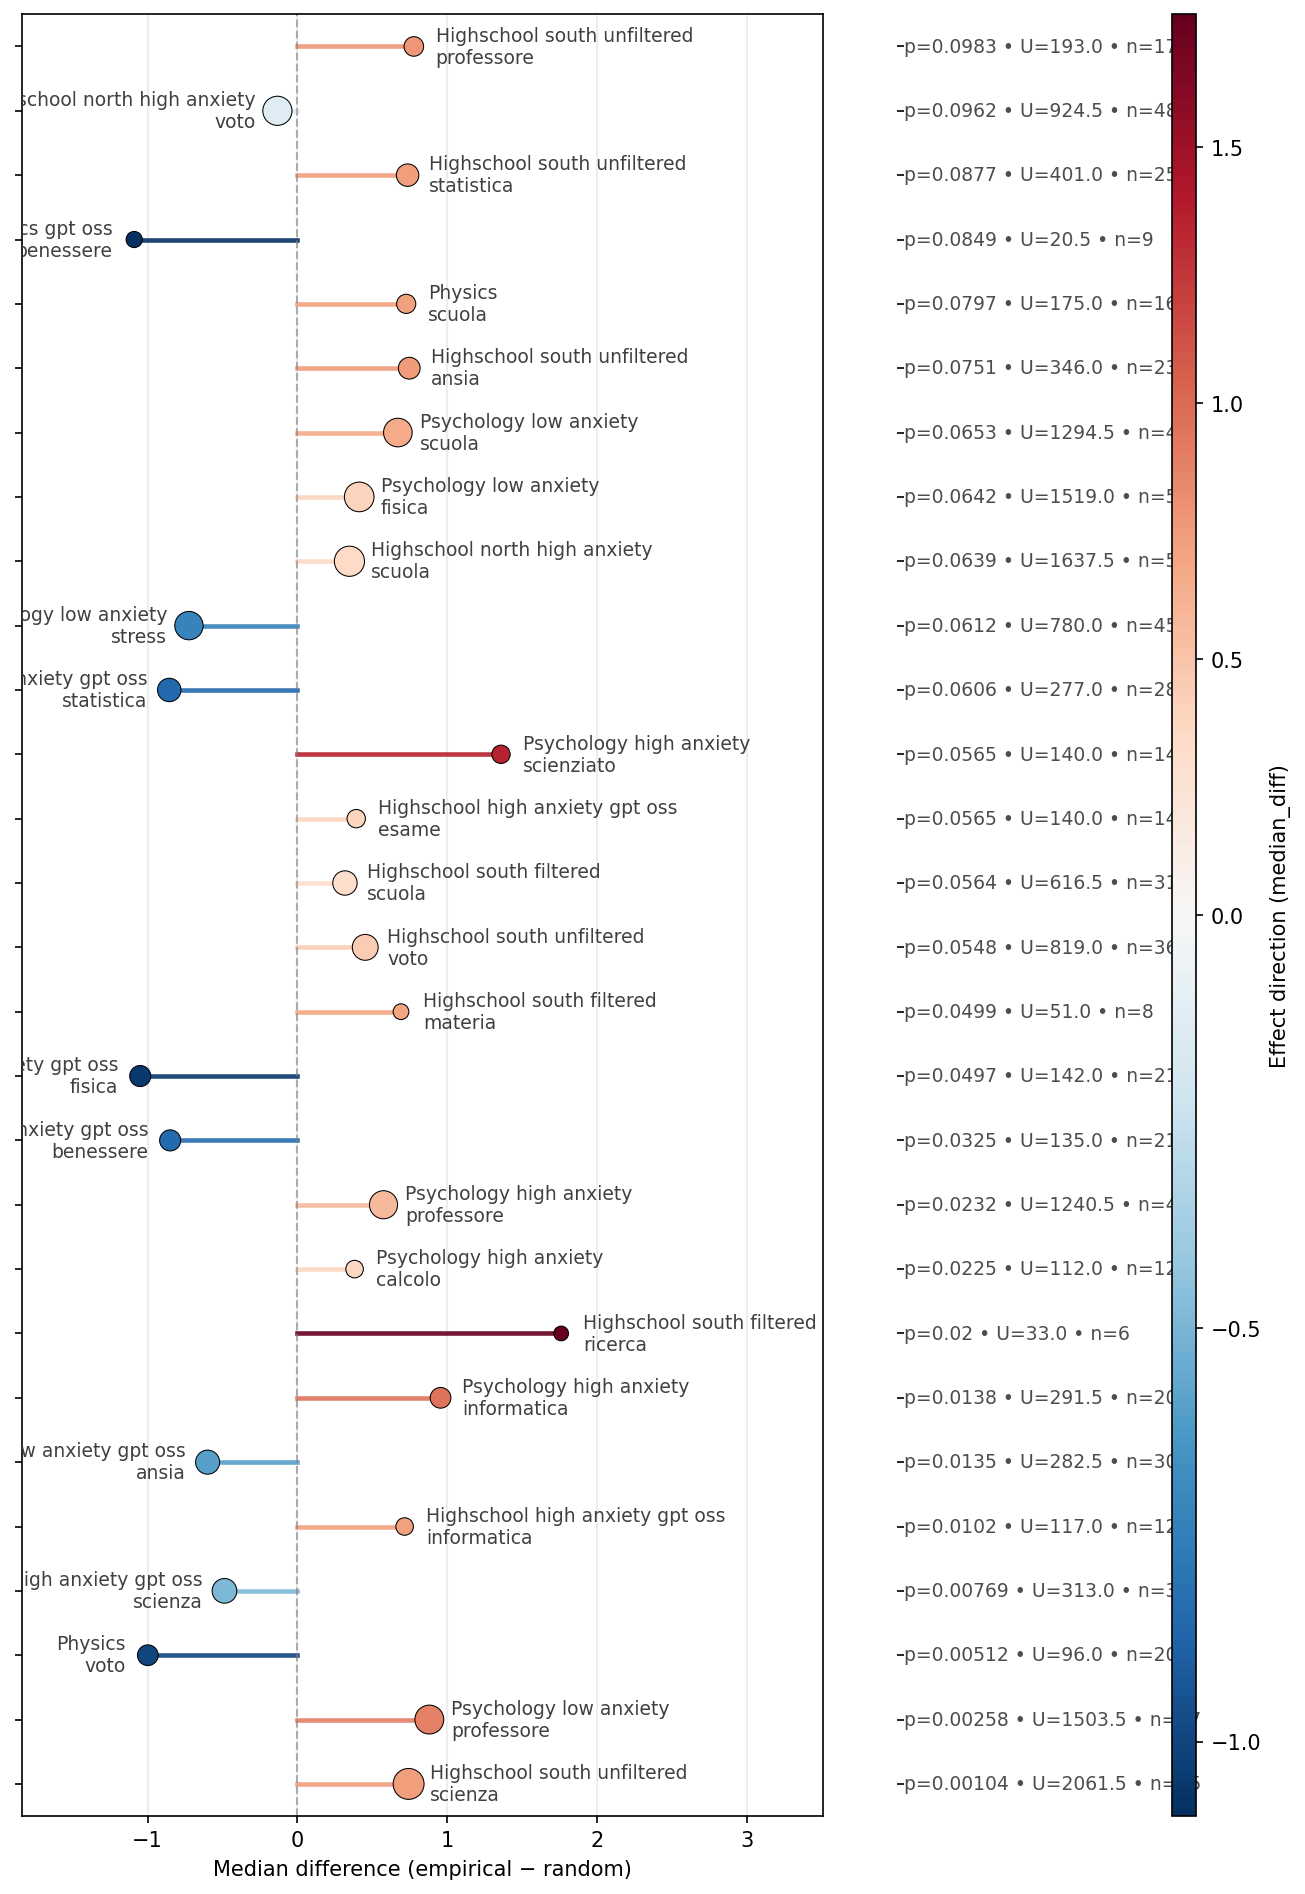

In [9]:
# Example usage (reads the CSV created above and plots it):
_ = plot_significant_concreteness(csv_filename="significant_concreteness_table_no_paths.csv")